# Is the test set really unseen? Duplicates, label noise and learning curves

**Module 04.2 · my implementation**, Seid Adem

> **Why this matters, in plain language.** A test score only means something if the test examples are genuinely
> new to the model. If the same sentence sits in both the training and the test set, the model can simply *remember*
> its label, and the score overstates how it will do on new text. This is called **data leakage**, and the course
> slides list "suspiciously good scores" as its warning sign. ([Lessons](../LESSONS.md))
>
> The opposite problem matters too: if the *labels* are inconsistent (the same sentence labelled differently in
> different places), no model can reach 100 %, and chasing the last few percent is wasted effort.

This notebook checks the official PubMed 20k RCT splits for both problems, measures their effect on scores, and then
draws **learning curves**: how the score grows with the amount of training data, the course slides' tool for deciding
whether to collect more data or build a better model.

The duplicate search is in [`src/dsls/evaluation.py`](../../../src/dsls/evaluation.py) (`normalise_text`,
`nearest_neighbours`, unit-tested).

In [1]:
import time
import warnings
from pathlib import Path

import datasets
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from datasets import load_dataset
from IPython.display import display
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import f1_score

from dsls.evaluation import nearest_neighbours, normalise_text
from dsls.textclf import (
    MLPClassifier,
    make_loader,
    pick_device,
    position_features,
    predict_proba,
    train_with_early_stopping,
)

warnings.filterwarnings("ignore", category=FutureWarning)
datasets.utils.logging.set_verbosity_error()
FIGURES = Path("figures")
FIGURES.mkdir(exist_ok=True)
sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_colwidth", 120)
SEED = 0
LABELS = ["background", "objective", "methods", "results", "conclusions"]
DEVICE = pick_device()

ds = load_dataset("armanc/pubmed-rct20k")
train, val, test = (ds[s].to_pandas() for s in ("train", "validation", "test"))
for df in (train, val, test):
    df["n_sentences"] = df.groupby("abstract_id")["sentence_id"].transform("max") + 1
    df["y"] = df["label"].map(LABELS.index)
    df["key"] = df["text"].map(normalise_text)
print({name: len(df) for name, df in (("train", train), ("validation", val), ("test", test))})

{'train': 176642, 'validation': 29672, 'test': 29578}


## 1 · Exact duplicates across the splits

> **In plain language.** Two sentences count as the same if they match after lower-casing and dropping numbers and
> punctuation ("Results: 45 patients…" = "results patients…"). The dataset replaces every number with `@`, so many
> sentences already differ only in their numbers.

In [2]:
train_keys = set(train["key"])
test["in_train"] = test["key"].isin(train_keys)
val["in_train"] = val["key"].isin(train_keys)
print(
    f"test sentences with an exact copy in train:       {test['in_train'].sum():5,} ({test['in_train'].mean():.1%})"
)
print(
    f"validation sentences with an exact copy in train: {val['in_train'].sum():5,} ({val['in_train'].mean():.1%})"
)
print(
    "\nlabels of the duplicated test sentences:", test.loc[test["in_train"], "label"].value_counts().to_dict()
)

copies = (
    test[test["in_train"]]
    .groupby("key")
    .agg(text=("text", "first"), label=("label", "first"), times_in_test=("text", "size"))
)
copies["times_in_train"] = copies.index.map(train["key"].value_counts())
copies.sort_values("times_in_train", ascending=False).head(12)[
    ["text", "label", "times_in_test", "times_in_train"]
]

test sentences with an exact copy in train:         403 (1.4%)
validation sentences with an exact copy in train:   380 (1.3%)

labels of the duplicated test sentences: {'methods': 243, 'results': 87, 'conclusions': 63, 'background': 5, 'objective': 5}


,text,label,times_in_test,times_in_train
key,,,,
this trial is registered with clinicaltrials gov number nct,"This trial is registered with ClinicalTrials.gov , number NCT@ .",methods,13,85
this study is registered with clinicaltrials gov number nct,"This study is registered with ClinicalTrials.gov , number NCT@ .",methods,11,68
this trial was registered at clinicaltrials gov as nct,This trial was registered at clinicaltrials.gov as NCT@ .,conclusions,11,58
randomized controlled trial,Randomized controlled trial .,methods,8,57
clinicaltrials gov number nct,"( ClinicalTrials.gov number , NCT@ . )",conclusions,7,49
analysis was by intention to treat,Analysis was by intention to treat .,methods,5,46
clinicaltrials gov nct,ClinicalTrials.gov : NCT@ .,conclusions,3,32
,@ .,objective,6,31
clinicaltrials gov identifier nct,CLINICALTRIALS.GOV IDENTIFIER : NCT@ .,conclusions,4,26


**1.4 % of test sentences (403) also appear word for word in the training set, and they are boilerplate, not leaked
abstracts.** The most frequent copies are trial-registration lines ("This trial is registered with ClinicalTrials.gov,
number NCT@."), "Randomized controlled trial." and "Analysis was by intention to treat." They recur because thousands
of authors write the same stock phrases. The validation set shows the same (1.3 %). The official split is by
abstract, so no abstract is shared; these copies come from different papers.

> **In plain language.** Not every duplicate is leakage. A deployed model *will* meet "This trial is registered
> with…" again and again, so having such sentences in the test set is realistic. The dangerous kind is a copy that
> only exists because of how the data was split, for example the same abstract on both sides.

## 2 · The same sentence with different labels

If identical text appears with *different* labels, the labels themselves are inconsistent. How often does that happen
inside the training set, and for the test sentences that have a copy in it?

In [3]:
labels_per_key = train.groupby("key")["label"].agg(lambda s: sorted(set(s)))
conflicting = labels_per_key[labels_per_key.map(len) > 1]
print(f"distinct training sentences with more than one label: {len(conflicting)} "
      f"(covering {train['key'].isin(conflicting.index).sum():,} training rows)")  # fmt: skip

dup = test[test["in_train"]]
agree = dup.apply(lambda r: labels_per_key[r["key"]] == [r["label"]], axis=1)
print(f"duplicated test sentences whose training copies all carry the test label: {agree.mean():.1%}")

examples = train[train["key"].isin(conflicting.index) & (train["key"].str.len() > 20)]
examples.groupby("key").agg(text=("text", "first"), labels=("label", lambda s: dict(s.value_counts()))).head(
    10
)

distinct training sentences with more than one label: 75 (covering 403 training rows)
duplicated test sentences whose training copies all carry the test label: 83.6%


,text,labels
key,,
a total of participants were randomized,A total of @ participants were randomized .,"{'results': 1, 'methods': 1}"
a total of patients were enrolled in this study,A total of @ patients were enrolled in this study .,"{'results': 1, 'methods': 1}"
a total of patients were included in the study,A total of @ patients were included in the study .,"{'results': 1, 'methods': 1}"
a total of patients were included in this study,A total of @ patients were included in this study .,"{'methods': 2, 'results': 1}"
adverse events were monitored,Adverse events were monitored .,"{'methods': 1, 'objective': 1}"
airway clearance was rapid,Airway clearance was rapid .,"{'results': 1, 'conclusions': 1}"
analysis was performed on an intention to treat basis,Analysis was performed on an intention-to-treat basis .,"{'results': 1, 'methods': 1}"
baseline characteristics were similar in both groups,Baseline characteristics were similar in both groups .,"{'methods': 1, 'results': 1}"
both treatments were well tolerated,Both treatments were well tolerated .,"{'results': 4, 'conclusions': 2}"


**The same sentence often carries different labels.** 75 distinct training sentences appear with more than one label
(403 training rows). "A total of @ patients were included in this study" is *methods* in two abstracts and *results* in
a third; "Both treatments were well tolerated" is *results* four times and *conclusions* twice. For the duplicated test
sentences, all training copies agree with the test label only **84 %** of the time. The trial-registration line in
section 1 is filed under *methods* by some authors and *conclusions* by others, depending on where they put it.

This is the same finding as the "confident mistakes" in [notebook 01](01_uncertainty_calibration_errors.ipynb): labels
come from the **section headings authors chose**, and authors don't agree. No model can be right on both copies of a
sentence labelled two ways, so part of the remaining error is a ceiling, not a model weakness.

## 3 · Near duplicates

Exact matching misses copies with a word changed ("The patients were…" vs "All patients were…"). For every test
sentence I find its **most similar training sentence** by TF-IDF cosine similarity (1 = same words; about 0.9 = one or
two words differ; below about 0.6 = merely on a similar topic).

compared 29,578 test sentences with 176,642 training sentences in 224 s


,similarity ≥,test sentences,share of test,nearest training label = test label
0,0.50,2545,0.086,0.884
1,0.70,911,0.031,0.920
2,0.80,630,0.021,0.919
3,0.90,443,0.015,0.932
4,0.95,412,0.014,0.930


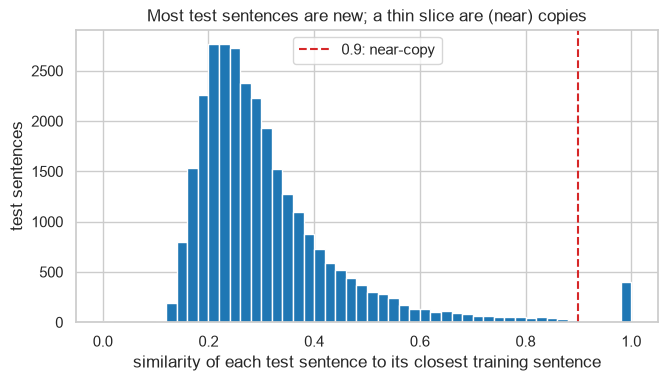

,text,nn_text,label,nn_label,nn_similarity
17713,Two hundred patients with a total number of @ AKs were enrolled .,Two hundred patients with a total of @ AKs were enrolled .,results,results,0.91
25770,Protocol registered at ClinicalTrials.gov ( NCT@ ) .,( Trial registered at ClinicalTrials.gov : NCT@ . ),conclusions,methods,0.85
15974,Tertiary care academic medical center .,The study was conducted in a tertiary care Academic Medical Center .,methods,methods,0.82
23076,The trial was registered with the Australian New Zealand Clinical Trials Registry ( ACTRN@ ) .,This trial is registered with the Australian New Zealand Clinical Trials Registry ( ACTRN@ ) .,methods,methods,0.88
18136,All patients were randomized into @ groups .,The patients were randomized into @ groups .,methods,methods,0.82
12648,"This was a phase III , two-group , cluster randomized , single-blinded , longitudinal design-guided study .","This was a phase III , two-group , cluster-randomized , single-blinded , longitudinal study .",methods,methods,0.88


In [4]:
start = time.perf_counter()
test["nn_similarity"], nn_index = nearest_neighbours(test["text"], train["text"])
test["nn_label"] = train["label"].to_numpy()[nn_index]
test["nn_text"] = train["text"].to_numpy()[nn_index]
print(
    f"compared {len(test):,} test sentences with {len(train):,} training sentences in {time.perf_counter() - start:.0f} s"
)

rows = []
for threshold in (0.5, 0.7, 0.8, 0.9, 0.95):
    near = test["nn_similarity"] >= threshold
    rows.append({"similarity ≥": threshold, "test sentences": int(near.sum()), "share of test": near.mean(),
                 "nearest training label = test label": (test["nn_label"] == test["label"])[near].mean()})  # fmt: skip
display(pd.DataFrame(rows).round(3))

fig, ax = plt.subplots(figsize=(7.5, 3.8))
ax.hist(test["nn_similarity"], bins=50, color="tab:blue")
ax.axvline(0.9, color="tab:red", ls="--", label="0.9: near-copy")
ax.set(xlabel="similarity of each test sentence to its closest training sentence", ylabel="test sentences",
       title="Most test sentences are new; a thin slice are (near) copies")  # fmt: skip
ax.legend()
fig.savefig(FIGURES / "05_nearest_training_sentence.png", dpi=150, bbox_inches="tight")
plt.show()

test[(test["nn_similarity"] >= 0.8) & (test["nn_similarity"] < 0.99)].sample(6, random_state=SEED)[
    ["text", "nn_text", "label", "nn_label", "nn_similarity"]
].round(2)

**Near copies add little: 1.5 % of test sentences have a training sentence with similarity ≥ 0.9, almost all of them
the exact copies already found.** The histogram shows most test sentences are genuinely new (typical similarity to
their closest training sentence: 0.2–0.4), with a thin spike at 1.0. The near copies are the same stock phrases with a
word changed ("All patients were randomized…" vs "The patients were randomized…").

Even the nearest training sentence's label matches the test label only **93 %** of the time at similarity ≥ 0.9. A
model that perfectly memorised the training set would get about 7 % of these "free" sentences wrong.

## 4 · Do the duplicates inflate the score?

The direct test: train a model on **all** 15,000 training abstracts (so it has seen every duplicate), then compare its
accuracy on duplicated and new test sentences, and recompute the overall score **without** them.

In [5]:
vec = TfidfVectorizer(ngram_range=(1, 2), min_df=2, sublinear_tf=True, max_features=50_000)
model = LogisticRegression(max_iter=3000, C=5).fit(vec.fit_transform(train["text"]), train["y"])
test["pred"] = model.predict(vec.transform(test["text"]))
test["correct"] = test["pred"] == test["y"]

groups = {"exact copy in train": test["in_train"],
          "near copy (similarity ≥ 0.9)": (test["nn_similarity"] >= 0.9) & ~test["in_train"],
          "new (similarity < 0.9)": test["nn_similarity"] < 0.9}  # fmt: skip
display(
    pd.DataFrame(
        {g: {"sentences": int(m.sum()), "accuracy": test.loc[m, "correct"].mean()} for g, m in groups.items()}
    ).T.round(3)
)

clean = test["nn_similarity"] < 0.9
for name, rows in (("full test set", test), ("without (near) copies", test[clean])):
    print(
        f"{name:22s} accuracy {rows['correct'].mean():.4f}  macro-F1 {f1_score(rows['y'], rows['pred'], average='macro'):.4f}"
    )

,sentences,accuracy
exact copy in train,403.0,0.933
near copy (similarity ≥ 0.9),49.0,0.959
new (similarity < 0.9),29135.0,0.815


full test set          accuracy 0.8172  macro-F1 0.7465
without (near) copies  accuracy 0.8152  macro-F1 0.7456


**The copies are easier, but too few to move the score.** A logistic-regression model trained on all 15,000 abstracts
scores 93 % accuracy on exact copies against 82 % on new sentences. Removing every exact and near copy from the test
set changes accuracy by **−0.002** (0.817 → 0.815) and macro-F1 by **−0.001**. **The official PubMed 20k RCT test
scores are not inflated by duplicates.**

> **In plain language.** The leakage check came back clean, and that's a useful result: it means earlier numbers in
> this repo can be trusted. Compare 03.2 (crystallography), where the same kind of check *did* find a problem (0.93 →
> 0.74 AUC). Always run the check; don't assume the answer either way.

## 5 · Learning curves: would more data help?

> **In plain language.** A **learning curve** plots the score against the amount of training data, for both the
> training data itself and unseen data. The gap between them and the slope tell you what to do next
> ([Lessons](../LESSONS.md)):
> * **large gap, test curve still rising** → the model is memorising (*overfitting*); more data will help;
> * **small gap, both curves flat and low** → the model is too simple or the features too poor (*underfitting*); more
>   data won't help, better features or a better model will;
> * **both flat and high** → you are near what the data allows (here, partly set by the label noise in section 2).

Two models from 04.1: TF-IDF + logistic regression, and the PyTorch MLP with position features. Each is trained from
scratch on 50 to 15,000 abstracts (the vocabulary is rebuilt from each training subset) and scored on its own training
sentences and on the test set. The MLP still uses the validation set for early stopping.

In [6]:
def position(df):
    return position_features(df["sentence_id"], df["n_sentences"])


rng = np.random.default_rng(SEED)
order = rng.permutation(train["abstract_id"].unique())
sizes = [50, 100, 200, 400, 800, 1600, 3200, 7500, 15000]
curve = []
start = time.perf_counter()
for n in sizes:
    sub = train[train["abstract_id"].isin(order[:n])]
    vec = TfidfVectorizer(ngram_range=(1, 2), min_df=2, sublinear_tf=True, max_features=50_000)
    X_sub, X_test = vec.fit_transform(sub["text"]), vec.transform(test["text"])

    lr = LogisticRegression(max_iter=3000, C=5).fit(X_sub, sub["y"])
    for split, X, df in (("training data", X_sub, sub), ("test set", X_test, test)):
        curve.append({"model": "TF-IDF + LR", "abstracts": n, "split": split,
                      "macro-F1": f1_score(df["y"], lr.predict(X), average="macro")})  # fmt: skip

    mlp = MLPClassifier(X_sub.shape[1] + 12, len(LABELS), seed=SEED)
    train_with_early_stopping(
        mlp,
        make_loader(X_sub, sub["y"], position(sub), batch_size=256, shuffle=True, seed=SEED),
        make_loader(vec.transform(val["text"]), val["y"], position(val), batch_size=1024),
        score_fn=lambda t, p: f1_score(t, p, average="macro"), max_epochs=30, patience=3, device=DEVICE, seed=SEED,
    )  # fmt: skip
    for split, X, df in (("training data", X_sub, sub), ("test set", X_test, test)):
        p = predict_proba(mlp, make_loader(X, None, position(df), batch_size=1024)).argmax(1)
        curve.append(
            {
                "model": "MLP + position",
                "abstracts": n,
                "split": split,
                "macro-F1": f1_score(df["y"], p, average="macro"),
            }
        )
    print(f"{n:6,} abstracts done ({time.perf_counter() - start:.0f} s)")
curve = pd.DataFrame(curve)

    50 abstracts done (10 s)


   100 abstracts done (25 s)


   200 abstracts done (40 s)


   400 abstracts done (66 s)


   800 abstracts done (105 s)


 1,600 abstracts done (200 s)


 3,200 abstracts done (315 s)


 7,500 abstracts done (492 s)


15,000 abstracts done (804 s)


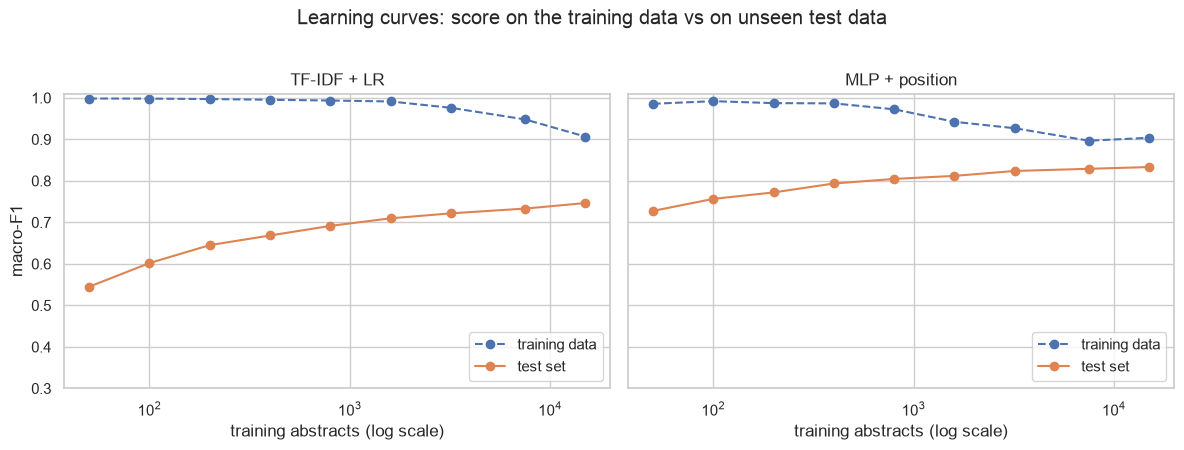

model     MLP + position               TF-IDF + LR              
split           test set training data    test set training data
abstracts                                                       
50                 0.728         0.986       0.545         0.998
100                0.757         0.992       0.602         0.998
200                0.772         0.987       0.645         0.997
400                0.794         0.987       0.668         0.995
800                0.805         0.972       0.692         0.993
1600               0.812         0.942       0.710         0.991
3200               0.824         0.927       0.722         0.976
7500               0.829         0.897       0.733         0.948
15000              0.833         0.904       0.747         0.907

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.4), sharey=True)
for ax, (name, part) in zip(axes, curve.groupby("model", sort=False), strict=True):
    for split, style in (("training data", "o--"), ("test set", "o-")):
        s = part[part["split"] == split]
        ax.plot(s["abstracts"], s["macro-F1"], style, label=split)
    ax.set_xscale("log")
    ax.set(title=name, xlabel="training abstracts (log scale)", ylim=(0.3, 1.01))
    ax.legend(loc="lower right")
axes[0].set_ylabel("macro-F1")
fig.suptitle("Learning curves: score on the training data vs on unseen test data", y=1.02)
fig.tight_layout()
fig.savefig(FIGURES / "06_learning_curves.png", dpi=150, bbox_inches="tight")
plt.show()
curve.pivot_table(index="abstracts", columns=["model", "split"], values="macro-F1").round(3)

**Reading the curves** (each point is a model trained from scratch on that many abstracts):

* **More data helps both models, with diminishing returns.** Each doubling of the data adds less: for the MLP, from
  7,500 to 15,000 abstracts adds only +0.004 macro-F1 (0.829 → 0.833); logistic regression still gains +0.014 (0.733 →
  0.747).
* **The training and test curves converge.** With little data, both models are near-perfect on their own training
  sentences (0.99) and much worse on new ones: they memorise. With more data, memorising every sentence becomes
  impossible: the training score falls and the gap closes (MLP: 0.26 at 50 abstracts, 0.07 at 15,000).
* **The MLP's test curve is flattening at about 0.83, with a small gap.** By the course slides' rules, that means
  more data won't help much: better features or a better model will. Exactly that happened in 04.1: PubMedBERT reading
  the words, plus the position written as text, reached **0.847 from only 400 abstracts**.
* **Features matter more than data:** the MLP with position trained on **100** abstracts (0.757) beats logistic
  regression trained on all **15,000** (0.747).

## Conclusions

1. **Check for duplicates, and look at what they are:** 1.4 % of test sentences have an exact copy in training, but
   they are stock phrases from different papers (trial registrations, "analysis was by intention to treat"), not
   leaked abstracts.
2. **They don't inflate the score:** removing all exact and near copies changes accuracy by −0.002 and macro-F1 by
   −0.001. A clean leakage check is a result worth reporting.
3. **The labels have a ceiling:** 75 training sentences carry more than one label, and at similarity ≥ 0.9 the
   nearest training label disagrees with the test label 7 % of the time. Labels come from authors' headings, and
   authors differ.
4. **Learning curves say what to do next:** the MLP's curve flattens near 0.83 with a small gap, so more data has
   little left to give, while better reading of the text does (PubMedBERT + position: 0.847 from 400 abstracts).
5. **Good features beat more data:** 100 abstracts with position features beat 15,000 without.

*Runtime: about 18 minutes on an Apple-silicon laptop: about 4 for the near-duplicate search and 13 for the learning
curves (18 model fits).*